# Actividad **Transformers y BERT**

## Preparación del entorno

In [17]:
# !pip install -q transformers datasets accelerate torch torchvision torchaudio

import torch, math, numpy as np, matplotlib.pyplot as plt
from transformers import (AutoTokenizer, AutoModel, AutoModelForMaskedLM,
                          AutoModelForSequenceClassification, pipeline)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
CUDA disponible: True


## Atención y Transformer

La **atención escalada producto punto** calcula la relevancia entre tokens:

$\text{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$

## BERT como *Masked Language Model* (MLM)

Usaremos `dccuchile/bert-base-spanish-wwm-cased` para predecir palabras enmascaradas en español.

In [ ]:
model_name_mlm = "dccuchile/bert-base-spanish-wwm-cased"  # BERT en español
fill_mask = pipeline("fill-mask", model=model_name_mlm, tokenizer=model_name_mlm)

oraciones = [
    "El [MASK] persiguió al ratón toda la noche.",
    "La IA moderna se basa en el mecanismo de [MASK].",
    "El modelo BERT es un tipo de [MASK]."
]

for s in oraciones:
    print("\nEntrada:", s)
    for pred in fill_mask(s, top_k=5):
        print(f"  → {pred['sequence']}  (score={pred['score']:.3f})")

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]


Entrada: El [MASK] persiguió al ratón toda la noche.
  → El gato persiguió al ratón toda la noche.  (score=0.452)
  → El ratón persiguió al ratón toda la noche.  (score=0.062)
  → El lobo persiguió al ratón toda la noche.  (score=0.062)
  → El perro persiguió al ratón toda la noche.  (score=0.047)
  → El zorro persiguió al ratón toda la noche.  (score=0.027)

Entrada: La IA moderna se basa en el mecanismo de [MASK].
  → La IA moderna se basa en el mecanismo de.  (score=0.184)
  → La IA moderna se basa en el mecanismo de activación.  (score=0.040)
  → La IA moderna se basa en el mecanismo de transferencia.  (score=0.040)
  → La IA moderna se basa en el mecanismo de salto.  (score=0.021)
  → La IA moderna se basa en el mecanismo de control.  (score=0.016)

Entrada: El modelo BERT es un tipo de [MASK].
  → El modelo BERT es un tipo de modelo.  (score=0.112)
  → El modelo BERT es un tipo de motocicleta.  (score=0.073)
  → El modelo BERT es un tipo de vehículo.  (score=0.071)
  → El modelo

## Visualizar la **atención** en BERT

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


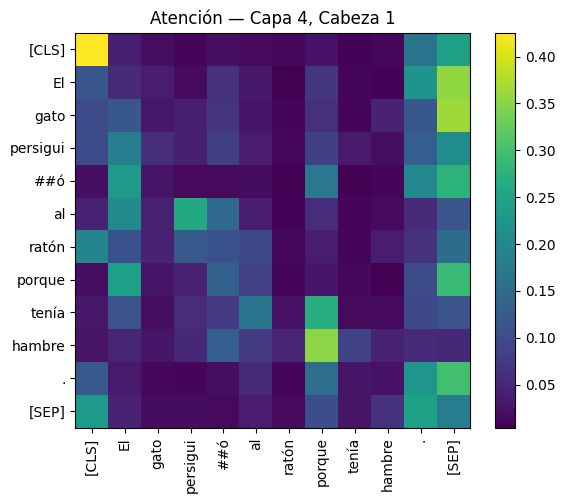

In [ ]:
import torch
import matplotlib.pyplot as plt

tok = AutoTokenizer.from_pretrained(model_name_mlm)
bert_enc = AutoModel.from_pretrained(model_name_mlm, output_attentions=True)

sent = "El gato persiguió al ratón porque tenía hambre."
enc = tok(sent, return_tensors="pt")
with torch.no_grad():
    out = bert_enc(**enc)
# out.attentions: list de [num_layers] con tensores (batch, heads, seq, seq)
atts = out.attentions

num_layers = len(atts)
num_heads = atts[0].shape[1]
layer_to_show = min(3, num_layers-1)   # tomar una capa intermedia
head_to_show  = 0

att = atts[layer_to_show][0, head_to_show].cpu().numpy()  # (seq, seq)
tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])

plt.figure(figsize=(6, 5))
plt.imshow(att, interpolation="nearest")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title(f"Atención — Capa {layer_to_show+1}, Cabeza {head_to_show+1}")
plt.colorbar()
plt.tight_layout()
plt.show()

## Clasificación rápida con BERT (sentimientos)

Usamos un BERT multilingüe entrenado para *sentiment analysis* (`nlptown/bert-base-multilingual-uncased-sentiment`).

In [ ]:
model_name_cls = "nlptown/bert-base-multilingual-uncased-sentiment"
sentiment = pipeline("sentiment-analysis", model=model_name_cls, tokenizer=model_name_cls)

ejemplos = [
    "La película fue excelente, la recomiendo.",
    "El servicio fue terrible y la comida estaba fría.",
    "Está bien, pero no volvería pronto."
]

for t in ejemplos:
    print(t, "→", sentiment(t)[0])

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

La película fue excelente, la recomiendo. → {'label': '5 stars', 'score': 0.6492040157318115}
El servicio fue terrible y la comida estaba fría. → {'label': '1 star', 'score': 0.7573900818824768}
Está bien, pero no volvería pronto. → {'label': '3 stars', 'score': 0.7223185896873474}


## Finetuning de BERT: detección de *hate speech*

Ahora afinamos nosotros un BERT para otra tarea. Partimos de `bert-base-uncased` (solo preentrenado con MLM) y lo entrenamos para clasificar tweets en `hate` / `non-hate`, usando el dataset `tweet_eval` (config `hate`, de HatEval 2019).

`AutoModelForSequenceClassification` agrega una capa lineal nueva sobre el token `[CLS]`. Se entrena todo el modelo, con un *learning rate* pequeño y pocas épocas.

In [18]:
from datasets import load_dataset
from transformers import DataCollatorWithPadding, TrainingArguments, Trainer

ds = load_dataset("cardiffnlp/tweet_eval", "hate")
tok_ft = AutoTokenizer.from_pretrained("bert-base-uncased")
ds_tok = ds.map(lambda b: tok_ft(b["text"], truncation=True, max_length=128), batched=True)
print(ds["train"][0])

{'text': '@user nice new signage. Are you not concerned by Beatlemania -style hysterical crowds crongregating on you…', 'label': 0}


In [22]:
model_ft = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", num_labels=2,
    id2label={0: "non-hate", 1: "hate"}, label2id={"non-hate": 0, "hate": 1})

def accuracy(eval_pred):
    logits, labels = eval_pred
    return {"accuracy": (logits.argmax(-1) == labels).mean()}

args = TrainingArguments(output_dir="bert-hate", num_train_epochs=3, learning_rate=2e-5,
                         per_device_train_batch_size=32, eval_strategy="epoch",
                         save_strategy="no", fp16=torch.cuda.is_available(), report_to="none")

trainer = Trainer(model=model_ft, args=args, train_dataset=ds_tok["train"],
                  eval_dataset=ds_tok["validation"],
                  data_collator=DataCollatorWithPadding(tok_ft), compute_metrics=accuracy)
trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.504753,0.745000
2,0.443517,0.469664,0.788000
3,0.443517,0.513303,0.781000


TrainOutput(global_step=846, training_loss=0.37445490410987364, metrics={'train_runtime': 107.0932, 'train_samples_per_second': 252.117, 'train_steps_per_second': 7.9, 'total_flos': 982218236320320.0, 'train_loss': 0.37445490410987364, 'epoch': 3.0})

In [20]:
hate_clf = pipeline("text-classification", model=trainer.model, tokenizer=tok_ft,
                    device=0 if torch.cuda.is_available() else -1)

for t in ["I hate Mondays, I need more coffee.",
          "Women are just as capable engineers as men.",
          "Send them all back, these immigrants are invading our country."]:
    print(t, "→", hate_clf(t)[0])

I hate Mondays, I need more coffee. → {'label': 'non-hate', 'score': 0.9384632706642151}
Women are just as capable engineers as men. → {'label': 'non-hate', 'score': 0.8489096164703369}
Send them all back, these immigrants are invading our country. → {'label': 'hate', 'score': 0.9389688968658447}


In [23]:
pred = trainer.predict(ds_tok["test"])
print(classification_report(pred.label_ids, pred.predictions.argmax(-1),
                            target_names=["non-hate", "hate"], digits=3))

              precision    recall  f1-score   support

    non-hate      0.900     0.210     0.340      1718
        hate      0.472     0.968     0.634      1252

    accuracy                          0.529      2970
   macro avg      0.686     0.589     0.487      2970
weighted avg      0.719     0.529     0.464      2970



## Actividad

Usaremos el dataset `cardiffnlp/tweet_eval` con la configuración `emotion`: tweets en inglés etiquetados según la emoción que expresan, en 4 clases: **anger (0)**, **joy (1)**, **optimism (2)** y **sadness (3)**. Trae splits de train (3.257), validación (374) y test (1.421).

**Enunciado.** Usando como base el código del finetuning de BERT para *hate speech*:

1. Carguen el dataset `cardiffnlp/tweet_eval` con la configuración `emotion` y tokenicen la columna `text`, truncando a `max_length=128`.
2. Cambien el modelo a `roberta-base` (tanto el tokenizador como el modelo).
3. Ajusten el número de clases a **4**.
4. Entrenen por **4 épocas**.
6. Evalúen en el conjunto de **test** con `classification_report` de `sklearn`.

## 1. Carga Dataset

In [ ]:
from sklearn.metrics import classification_report
from datasets import load_dataset
from transformers import DataCollatorWithPadding, TrainingArguments, Trainer

def accuracy(eval_pred):
    logits, labels = eval_pred
    return {"accuracy": (logits.argmax(-1) == labels).mean()}

ds_emo = load_dataset("cardiffnlp/tweet_eval", "emotion")
print(ds_emo)

labels_emo = ["anger", "joy", "optimism", "sadness"]
id2label_emo = dict(enumerate(labels_emo))
label2id_emo = {v: k for k, v in id2label_emo.items()}